# 02 · Demand patterns: when do restaurants fill up?

**Question:** how do covers change over time, across the week and on holidays? How predictable is each restaurant, and how much of its demand comes through online reservations?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

daily = pd.read_csv("../data/processed/daily_visits.csv", parse_dates=["visit_date"])
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def clean_axes(ax, keep="bottom"):
    """Light chart style: no top/right frame, soft grid."""
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(side == keep)
    ax.spines[keep].set_color("#ccc")
    ax.tick_params(length=0, labelsize=9)

print(daily.shape)

(252108, 15)


## 2.1 Covers over time

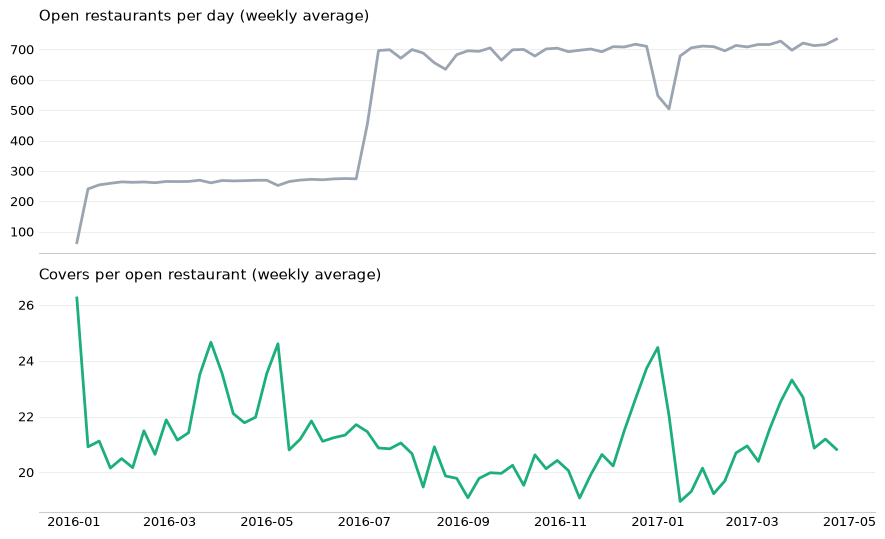

Open restaurants per day: min 48, max 799


In [2]:
by_day = daily.groupby("visit_date").agg(open_restaurants=("air_store_id", "nunique"),
                                         covers=("visitors", "sum"))
by_day["covers_per_restaurant"] = by_day["covers"] / by_day["open_restaurants"]
weekly = by_day.resample("W").mean()

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].plot(weekly.index, weekly["open_restaurants"], color="#9aa5b1", linewidth=2)
axes[0].set_title("Open restaurants per day (weekly average)", loc="left", fontsize=11)
axes[1].plot(weekly.index, weekly["covers_per_restaurant"], color="#1baf7a", linewidth=2)
axes[1].set_title("Covers per open restaurant (weekly average)", loc="left", fontsize=11)
for ax in axes:
    clean_axes(ax)
    ax.grid(axis="y", color="#eee", linewidth=0.8)
plt.tight_layout()
plt.savefig("../figures/covers_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Open restaurants per day: min {by_day['open_restaurants'].min()}, max {by_day['open_restaurants'].max()}")

The top chart shows why totals would mislead: when many restaurants start reporting, total covers jump without any change in demand. Covers per open restaurant (bottom) is the measure used from here on.

## 2.2 Day of the week and holidays

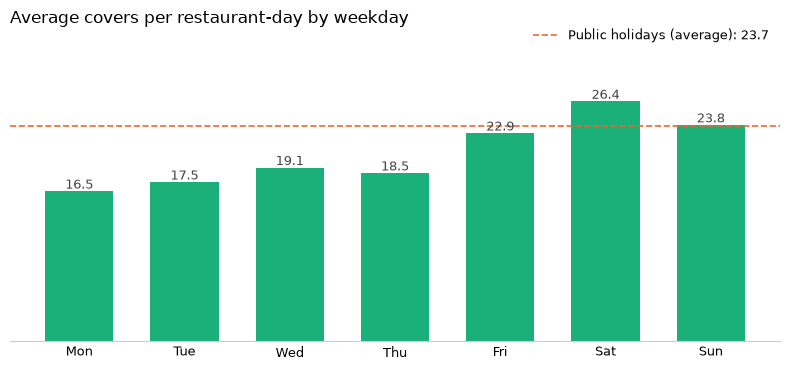

day_of_week
Monday       16.5
Tuesday      17.5
Wednesday    19.1
Thursday     18.5
Friday       22.9
Saturday     26.4
Sunday       23.8
Name: visitors, dtype: float64
Busiest day: Saturday (26.4) | quietest: Monday (16.5) | ratio 1.60x
Public holidays: 23.7 covers on average


In [3]:
dow = (daily[daily["holiday_flg"] == 0]
       .groupby("day_of_week")["visitors"].mean()
       .reindex(DOW).round(1))
holiday_avg = daily.loc[daily["holiday_flg"] == 1, "visitors"].mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar([d[:3] for d in DOW], dow.values, color="#1baf7a", width=0.65)
for b, v in zip(bars, dow.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f}", ha="center", fontsize=9, color="#444")
ax.axhline(holiday_avg, color="#eb6834", linewidth=1.2, linestyle="--",
           label=f"Public holidays (average): {holiday_avg:.1f}")
ax.set_ylim(0, max(dow.max(), holiday_avg) * 1.2)
ax.legend(frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(1, 1.0))
clean_axes(ax)
ax.yaxis.set_visible(False)
ax.set_title("Average covers per restaurant-day by weekday", loc="left", fontsize=12, pad=22)
plt.tight_layout()
plt.savefig("../figures/covers_by_weekday.png", dpi=150, bbox_inches="tight")
plt.show()

peak, low = dow.idxmax(), dow.idxmin()
print(dow)
print(f"Busiest day: {peak} ({dow.max()}) | quietest: {low} ({dow.min()}) | ratio {dow.max() / dow.min():.2f}x")
print(f"Public holidays: {holiday_avg:.1f} covers on average")

## 2.3 Cuisine types

In [4]:
genre = daily.groupby("air_genre_name").agg(
    restaurants=("air_store_id", "nunique"),
    avg_covers=("visitors", "mean"),
    reservation_share=("res_all", "sum"),
    covers=("visitors", "sum"),
)
genre["reservation_share"] = (genre["reservation_share"] / genre["covers"] * 100).round(1)
genre["avg_covers"] = genre["avg_covers"].round(1)
genre = genre.drop(columns="covers").sort_values("restaurants", ascending=False)
genre

,restaurants,avg_covers,reservation_share
air_genre_name,,,
Izakaya,197,23.1,14.0
Cafe/Sweets,181,22.6,1.2
Dining bar,108,18.7,9.7
Italian/French,102,22.6,12.1
Bar/Cocktail,79,13.3,2.3
Japanese food,63,19.6,12.2
Other,27,19.9,1.6
Yakiniku/Korean food,23,21.2,17.1
Western food,16,22.3,14.5


## 2.4 How predictable is each restaurant?

In [5]:
per_store = daily.groupby("air_store_id")["visitors"].agg(["median", "mean", "std", "count"])
per_store = per_store[per_store["count"] >= 60]
per_store["cv"] = per_store["std"] / per_store["mean"]   # coefficient of variation

print(f"Restaurants with 60+ open days: {len(per_store)}")
print(per_store[["median", "cv"]].describe(percentiles=[0.25, 0.5, 0.75]).round(2))
print(f"Share of restaurants whose daily covers vary by more than 50% of their mean (CV > 0.5): "
      f"{(per_store['cv'] > 0.5).mean():.1%}")

Restaurants with 60+ open days: 822
       median      cv
count  822.00  822.00
mean    19.28    0.58
std     10.87    0.22
min      1.00    0.17
25%     10.62    0.45
50%     17.00    0.55
75%     27.00    0.67
max     83.00    2.56
Share of restaurants whose daily covers vary by more than 50% of their mean (CV > 0.5): 63.1%


The **coefficient of variation** (standard deviation ÷ mean) compares variability across restaurants of different sizes. A restaurant with CV 0.5 typically moves 50% around its average day: preparing for an "average" day would often mean too much or too little.

## 2.5 How much of the demand is booked online?

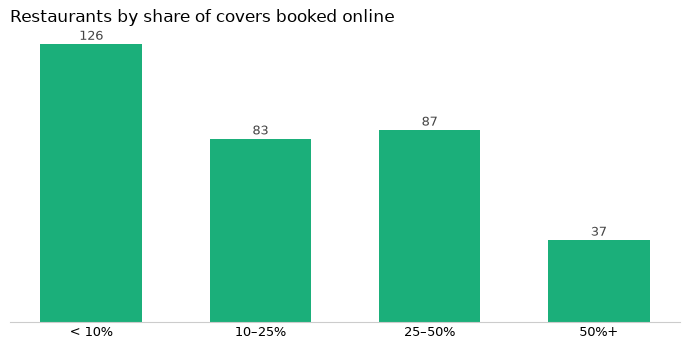

Restaurants with reservation data: 333
Covers booked online: 20.8% (known the day before: 16.8%)
share
< 10%     126
10–25%     83
25–50%     87
50%+       37
Name: count, dtype: int64


In [6]:
res_stores = daily[daily["has_reservations"] == 1]
share_all = res_stores["res_all"].sum() / res_stores["visitors"].sum()
share_d1 = res_stores["res_d1"].sum() / res_stores["visitors"].sum()

store_share = (res_stores.groupby("air_store_id")[["res_all", "visitors"]].sum()
                 .assign(share=lambda d: (d["res_all"] / d["visitors"]).clip(upper=1)))

bins = [0, 0.1, 0.25, 0.5, 1.0]
labels = ["< 10%", "10–25%", "25–50%", "50%+"]
dist = pd.cut(store_share["share"], bins=bins, labels=labels, include_lowest=True).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(labels, dist.values, color="#1baf7a", width=0.6)
for b, v in zip(bars, dist.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v}", ha="center", fontsize=9, color="#444")
clean_axes(ax)
ax.yaxis.set_visible(False)
ax.set_title("Restaurants by share of covers booked online", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/reservation_share.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Restaurants with reservation data: {len(store_share)}")
print(f"Covers booked online: {share_all:.1%} (known the day before: {share_d1:.1%})")
print(dist)

In [7]:
corr = (res_stores.groupby("air_store_id")
          .apply(lambda g: g["res_d1"].corr(g["visitors"]) if g["res_d1"].std() > 0 else np.nan,
                 include_groups=False)
          .dropna())
print(f"Median within-restaurant correlation between reservations known the day before and covers: {corr.median():.2f}")

Median within-restaurant correlation between reservations known the day before and covers: 0.33


Online reservations are a **partial** view of demand: the rest is walk-ins and bookings by phone. Their value for forecasting is tested directly in notebook 03, by training the same model with and without them.

## Summary

In [8]:
print(f"Busiest weekday: {peak} ({dow.max():.1f} covers) vs quietest {low} ({dow.min():.1f}): {dow.max() / dow.min():.2f}x")
print(f"Public holidays: {holiday_avg:.1f} covers per restaurant-day")
print(f"Median restaurant: {per_store['median'].median():.0f} covers/day, median CV {per_store['cv'].median():.2f}, "
      f"{(per_store['cv'] > 0.5).mean():.1%} with CV > 0.5")
print(f"Online share of covers (restaurants with reservation data): {share_all:.1%} all, {share_d1:.1%} known the day before")
print(f"Restaurants with < 10% of covers booked online: {dist.iloc[0]} of {len(store_share)}")
print(f"Median correlation reservations (D-1) vs covers: {corr.median():.2f}")

Busiest weekday: Saturday (26.4 covers) vs quietest Monday (16.5): 1.60x
Public holidays: 23.7 covers per restaurant-day
Median restaurant: 17 covers/day, median CV 0.55, 63.1% with CV > 0.5
Online share of covers (restaurants with reservation data): 20.8% all, 16.8% known the day before
Restaurants with < 10% of covers booked online: 126 of 333
Median correlation reservations (D-1) vs covers: 0.33


## Findings

1. **Totals mislead.** The number of restaurants reporting changes over time, so demand is compared per open restaurant.
2. **The week sets the rhythm.** Saturday averages 26.4 covers per restaurant vs 16.5 on Monday (1.6x). Public holidays (23.7) look like a weekend day.
3. **Daily demand is volatile.** The median restaurant has a coefficient of variation of 0.55, and 63.1% of restaurants move by more than half of their average day: planning for an "average day" is often far off.
4. **Online reservations show only part of the demand.** In restaurants with reservation data, 20.8% of covers are booked online (16.8% known the day before); 126 of 333 restaurants (38%) get less than 10% of covers online. The median correlation between reservations and covers is 0.33: a useful signal, but weak on its own.